In [1]:
import os, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.analysis.data import *
from cifresignificative.viz.style import *
apply_style()
panel = load_panel()


# 13 - Where in the economy is the productivity gap? 62 industries (NACE A*64)
Notebook 08 showed that Italy's weak productivity is a *within-sector* problem at the 9-section level. Here the same accounting is done for 62 industries (market sectors; real estate and non-market services excluded) to see which industries carry the gap. Real output per hour, chain-linked 2020 euros; only growth is compared across countries.

members with industry data: 26 | left out: [] | industries per member (min/median): 4 53 | Italy: 57
Aggregate within-industry contribution 2005-2024 (% of 2005 output per hour): Italy 5.8 | sum of medians 18.1
Reallocation across the 62 industries: Italy 1.0 | median of others 3.1


,hours_share_2005,growth_pa,within,realloc,within_median_others,growth_median_others,gap_within
ind,,,,,,,
I,6.41,-1.61,-1.39,2.10,0.09,0.11,-1.49
C26,0.68,0.78,0.15,-0.16,1.30,3.90,-1.15
A01,6.54,0.08,0.04,-0.33,1.04,2.13,-0.99
H52,1.82,-1.34,-0.60,0.66,0.30,0.92,-0.90
J61,0.64,3.91,1.34,-0.52,2.16,3.87,-0.82
F,9.58,-0.36,-0.63,-0.10,0.13,0.15,-0.76
M69_M70,3.69,-0.09,-0.08,1.50,0.58,0.76,-0.66
N79,0.24,-9.63,-0.63,0.06,0.00,0.00,-0.63
C28,2.56,0.46,0.29,-0.05,0.87,2.10,-0.58


The 10 industries with the largest shortfall explain 69% of the total shortfall (sum of gaps -12.3 pp)


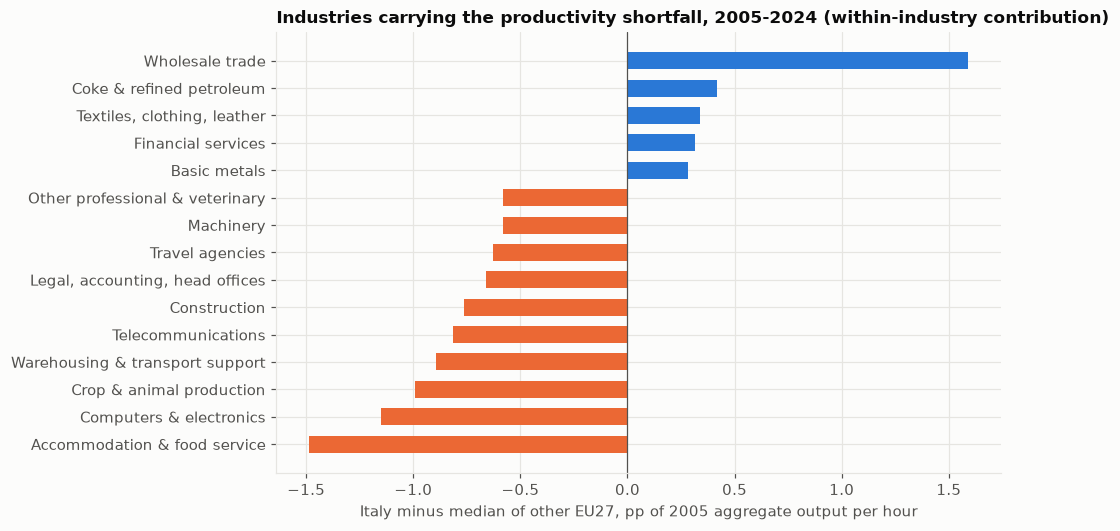

In [2]:
s64 = load_sectors64(); A, B = 2005, 2024  # 2025 is not usable at A*64 detail yet (Eurostat release of 21 Oct 2026: Italy has 15 of 57 industries); an industry enters a country's table only with output and hours in both years
pv = s64.pivot_table(index="iso3", columns=["nace_r2", "year"], values="prod"); hv = s64.pivot_table(index="iso3", columns=["nace_r2", "year"], values="hours_ths")
inds = sorted({n for n, _ in pv.columns})
def contributions(iso):
    rows = []
    for n in inds:
        try: p0, p1, h0, h1 = pv.loc[iso, (n, A)], pv.loc[iso, (n, B)], hv.loc[iso, (n, A)], hv.loc[iso, (n, B)]
        except KeyError: continue
        if min(p0, p1, h0, h1) > 0 and np.isfinite([p0, p1, h0, h1]).all(): rows.append((n, p0, p1, h0, h1))
    d = pd.DataFrame(rows, columns=["ind", "p0", "p1", "h0", "h1"]).set_index("ind")
    s0, s1 = d.h0 / d.h0.sum(), d.h1 / d.h1.sum(); base = (s0 * d.p0).sum()
    return pd.DataFrame({"hours_share_2005": s0 * 100, "growth_pa": np.log(d.p1 / d.p0) / (B - A) * 100, "within": s0 * (d.p1 - d.p0) / base * 100, "realloc": (s1 - s0) * d.p0 / base * 100})
eu = [c for c in EU27_ISO3 if c in pv.index and c != ITALY]
ci = contributions(ITALY); cm = {c: contributions(c) for c in eu}; cm = {c: v for c, v in cm.items() if len(v)}  # a member without any industry in both years (Bulgaria, Latvia in 2025) must not count as a zero
print('members with industry data:', len(cm), '| left out:', sorted(set(eu) - set(cm)), '| industries per member (min/median):', min(len(v) for v in cm.values()), int(np.median([len(v) for v in cm.values()])), '| Italy:', len(ci))
med_within = pd.DataFrame({c: v["within"] for c, v in cm.items()}).median(axis=1); med_growth = pd.DataFrame({c: v["growth_pa"] for c, v in cm.items()}).median(axis=1)
tab = ci.join(med_within.rename("within_median_others")).join(med_growth.rename("growth_median_others"))
tab["gap_within"] = tab.within - tab.within_median_others
print(f"Aggregate within-industry contribution 2005-2024 (% of 2005 output per hour): Italy {ci.within.sum():.1f} | sum of medians {med_within.sum():.1f}")
print("Reallocation across the 62 industries: Italy %.1f | median of others %.1f" % (ci.realloc.sum(), pd.Series({c: v.realloc.sum() for c, v in cm.items()}).median()))
worst = tab.sort_values("gap_within").head(10); best = tab.sort_values("gap_within").tail(5)
display(worst.round(2)); print("The 10 industries with the largest shortfall explain %.0f%% of the total shortfall (sum of gaps %.1f pp)" % (worst.gap_within.sum() / tab.gap_within.sum() * 100, tab.gap_within.sum()))
plot = pd.concat([worst, best]).sort_values("gap_within")
fig, ax = plt.subplots(figsize=(8.5, 5.2)); ax.barh(range(len(plot)), plot.gap_within, color=[ITALY_C if v >= 0 else EU_C for v in plot.gap_within], height=0.62)
ax.set_yticks(range(len(plot)), [A64_LABELS.get(n, n) for n in plot.index]); ax.axvline(0, color=INK2, lw=0.8); ax.set_xlabel("Italy minus median of other EU27, pp of 2005 aggregate output per hour")
ax.set_title("Industries carrying the productivity shortfall, 2005-2024 (within-industry contribution)"); save(fig, "13_industry_gap")

,hours_share_2005,growth_pa,within,realloc,within_median_others,growth_median_others,gap_within
ind,,,,,,,
G47,11.45,1.21,1.67,-0.75,2.22,1.87,-0.56
F,9.58,-0.36,-0.63,-0.10,0.13,0.15,-0.76
G46,7.16,2.71,3.85,-0.81,2.26,1.27,1.59
A01,6.54,0.08,0.04,-0.33,1.04,2.13,-0.99
I,6.41,-1.61,-1.39,2.10,0.09,0.11,-1.49
H49,3.70,0.24,0.20,-0.10,0.41,0.50,-0.21
M69_M70,3.69,-0.09,-0.08,1.50,0.58,0.76,-0.66
C13-C15,3.53,1.66,1.04,-1.09,0.70,2.06,0.34
N80-N82,3.53,-0.77,-0.39,0.81,0.13,0.53,-0.52


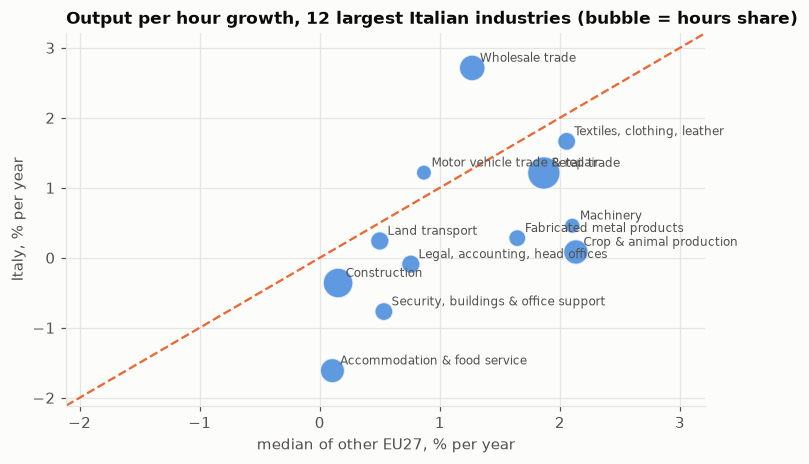

In [3]:
# Productivity growth vs hours weight for the biggest Italian industries
big = tab.sort_values("hours_share_2005", ascending=False).head(12)
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.scatter(big.growth_median_others, big.growth_pa, s=big.hours_share_2005 * 40, color=ITALY_C, alpha=0.75, edgecolor=SURFACE)
for n, r in big.iterrows(): ax.annotate(A64_LABELS.get(n, n), (r.growth_median_others, r.growth_pa), xytext=(5, 4), textcoords="offset points", fontsize=8, color=INK2)
lim = [min(big.growth_pa.min(), big.growth_median_others.min()) - 0.5, max(big.growth_pa.max(), big.growth_median_others.max()) + 0.5]
ax.plot(lim, lim, color=EU_C, ls="--", lw=1.5); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("median of other EU27, % per year"); ax.set_ylabel("Italy, % per year"); ax.set_title("Output per hour growth, 12 largest Italian industries (bubble = hours share)"); save(fig, "13_industry_scatter")
display(big.round(2))

## Takeaways (Eurostat national accounts, A*64 industries; 2005-2024; 2025 is not usable at this detail yet: Italy has 15 of 57 industries)
- **The shortfall is spread over many industries.** Within-industry productivity growth added 5.8% to Italy's aggregate output per hour over 2005-2024 against 18.1% for the (sum of per-industry) medians of the other 26 members: a gap of 12.3 pp (57 Italian industries, 41 of them below the median). Reallocation of hours across industries added 1.0 vs 3.1 for the median, so shifting workers between industries is not the story.
- **The 10 largest shortfalls account for 69% of the total:** accommodation & food service (-1.5 pp; output per hour -1.6% a year), computers & electronics (-1.2), crop & animal production (-1.0), warehousing & transport support (-0.9), telecommunications (-0.8), construction (-0.8), legal, accounting & head offices (-0.7), travel agencies (-0.6; a very small industry whose output per hour falls 9.6% a year, to be read with care), machinery (-0.6) and other professional & veterinary services (-0.6).
- **Construction is a 2005-2019 story.** Over 2005-2019 it was 2.5 pp of an 11.6 pp shortfall (about a fifth; output per hour -1.4% a year against +0.4%, 9.6% of hours); with 2020-2024 included it is 0.8 pp of 12.3 (-0.4% a year against +0.1%), because Italian construction productivity rises after 2019 (see notebook 08). The 2005-2019 results on the revised data are the same to the first decimal (within-industry 4.2 vs 15.8; ten largest 75%), so the change comes from the period, not from the revisions.
- **Offsets exist:** wholesale trade (+1.6 pp better than the median; +2.7% a year), refined petroleum (+0.4), textiles and clothing (+0.3), financial services (+0.3), basic metals (+0.3).
- Caveats: services deflators and hours are less well measured, so industry rankings are indicative; some members have few industries with data in both years (minimum 4, median 53), which makes their reallocation terms less comparable; the data cannot tell whether low productivity reflects firm size, regulation, skills or measurement, which would need firm-level data.